# 03_08 — PatchTST: Transfer Learning Austrália → Brasil (240 → 24 h)

**Objetivo:** avaliar no Brasil, exclusivamente com a potência histórica, três origens de pesos: (a) treinamento do zero (Scratch), (b) pré-treinamento australiano univariado e (c) pré-treinamento australiano com reconstrução compartilhada de meteorologia + potência. Os dois últimos foram gerados pelo `03_07`.

As estratégias são **Source Only**, **Head-only (encoder congelado)** e **Fine-tuning completo** para cada origem. Baselines: persistência sazonal de 24 horas e regressão linear direta. Normalização Min–Max calculada somente com treino **brasileiro**; nenhum dado australiano bruto ou meteorologia é lido neste notebook.

**Critério de seleção:** MAE normalizado na validação brasileira. **Teste brasileiro permanece bloqueado** por padrão; apenas execute após escolher o protocolo. Janelas horárias sobrepostas são correlacionadas: use também avaliação com emissões espaçadas e múltiplas sementes como análises posteriores.

**Referências:** Nie et al. (2023), PatchTST; Bak et al. (2025), IEEE Access, DOI 10.1109/ACCESS.2025.3591040. Adaptação metodológica para destino exclusivamente univariado, não réplica fiel da configuração de cinco entradas do artigo.

## 1. Configurações, dispositivo e caminhos

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, random, json, copy, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as arquivo:
        for parte in iter(lambda: arquivo.read(1024*1024), b''):
            h.update(parte)
    return h.hexdigest()

def seed_tudo(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
    torch.backends.cudnn.benchmark = True
else:
    print('AVISO: GPU CUDA indisponível. Treino em CPU.')
RAIZ = next((f for f in [Path.cwd(), *Path.cwd().parents]
             if (f/'data/processed/sequencias_temporais_24h').is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError('Pasta data/processed/sequencias_temporais_24h não encontrada; execute 03_04 no projeto.')
TENSORES = RAIZ/'data/processed/sequencias_temporais_24h'

HISTORICO,HORIZONTE=240,24
SEEDS=[42]  # Devem existir os dois checkpoints correspondentes do 03_07 em cada seed
BATCH_SIZE=16
EPOCAS=50
PACIENCIA=10
LR_SCRATCH=1e-3
LR_ENCODER_TL=1e-4
LR_HEAD_TL=5e-4
WEIGHT_DECAY=1e-4
DELTA_HUBER=0.05
AVALIAR_TESTE_FINAL=False
DIR_AU=RAIZ/'reports/tcc/03_07_pretreino_patchtst'
SAIDA=RAIZ/'reports/tcc/03_08_tl_patchtst_brasil'/f'L{HISTORICO}_H{HORIZONTE}'
SAIDA.mkdir(parents=True,exist_ok=True)
print('Checkpoint AU:',DIR_AU,'| Saídas BR:',SAIDA)


GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Checkpoint AU: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_07_pretreino_patchtst | Saídas BR: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_08_tl_patchtst_brasil\L240_H24


## 2. Ler partições brasileiras e normalizar sem vazamento

In [2]:
def ler_npz(dominio, part):
    if dominio not in {'australia','brasil'} or part not in {'treino','validacao','teste'}:
        raise ValueError('Domínio/partição inválidos')
    arq = TENSORES/f'{dominio}_{part}_L{HISTORICO}_H{HORIZONTE}.npz'
    if not arq.is_file(): raise FileNotFoundError(f'Não encontrado: {arq}')
    with np.load(arq,allow_pickle=False) as z:
        d={k:z[k].copy() for k in z.files}
    required={'X','X_potencia','y','y_kw','features','capacidade_kw','timestamps_X','timestamps_y','emissao','mask_y_observado'}
    if missing:=required-set(d): raise ValueError(f'{arq.name}: campos faltantes {missing}')
    n=len(d['y']); c=5 if dominio=='australia' else 1
    assert d['X'].shape==(n,HISTORICO,c), (arq,d['X'].shape)
    assert d['X_potencia'].shape==(n,HISTORICO,1)
    assert d['y'].shape==(n,HORIZONTE) and d['y_kw'].shape==(n,HORIZONTE)
    esperado=(['Global_Horizontal_Radiation','Weather_Temperature_Celsius',
              'Weather_Relative_Humidity','Wind_Speed','Active_Power'] if c==5 else ['Active_Power'])
    if list(d['features'])!=esperado: raise ValueError(f'Ordenação de canais inesperada em {arq.name}')
    if not np.isfinite(d['X']).all() or not np.isfinite(d['y_kw']).all():
        raise ValueError('Dados não finitos no NPZ')
    if not d['mask_y_observado'].all(): raise ValueError('Alvos interpolados/não observados no NPZ')
    fator=float(d['capacidade_kw'])
    if not np.isfinite(fator) or fator<=0: raise ValueError('Fator antigo do 03_04 inválido')
    if not np.allclose(d['X'][:,:,-1],d['X_potencia'][:,:,0],atol=1e-6):
        raise ValueError('Potência nos canais incompatível')
    if not np.allclose(d['y']*fator,d['y_kw'],atol=1e-3,rtol=4e-5):
        raise ValueError('Alvos em kW inconsistentes com antigo fator do 03_04')
    if n:
        if not np.all(np.diff(d['timestamps_X'],axis=1)==np.timedelta64(1,'h')):
            raise ValueError('Histórico cruza lacuna temporal')
        if not np.all(np.diff(d['timestamps_y'],axis=1)==np.timedelta64(1,'h')):
            raise ValueError('Horizonte cruza lacuna temporal')
        if not np.all(d['timestamps_X'][:,-1]+np.timedelta64(1,'h')==d['emissao']):
            raise ValueError('Emissão incompatível com histórico')
        if not np.all(d['timestamps_y'][:,0]==d['emissao']):
            raise ValueError('Emissão incompatível com alvo')
    d.update(fator_antigo=fator,arquivo=str(arq),hash_sha256=sha256(arq))
    return d

def parametros_de_treino(raw):
    """Usa exclusivamente o período de treino; amostras sobrepostas não alteram extremos."""
    fator=raw['fator_antigo']
    baixo=min(float(raw['X_potencia'].min())*fator, float(raw['y_kw'].min()))
    alto=max(float(raw['X_potencia'].max())*fator, float(raw['y_kw'].max()))
    if not np.isfinite(alto-baixo) or alto<=baixo:
        raise ValueError('MinMax inválido')
    return {'min_kw':baixo,'max_kw':alto,'amplitude_kw':alto-baixo,
            'fator_original_03_04_kw':fator,'metodo':'minmax_treino_historicos_e_alvos',
            'clipping':False}

def normalizar(raw,escala):
    if not np.isclose(raw['fator_antigo'],escala['fator_original_03_04_kw']):
        raise ValueError('Fator antigo inconsistente entre partições')
    x=raw['X'].astype(np.float32).copy()
    potencia_kw=raw['X_potencia'][:,:,0].astype(np.float64)*raw['fator_antigo']
    x[:,:,-1]=((potencia_kw-escala['min_kw'])/escala['amplitude_kw']).astype(np.float32)
    y=((raw['y_kw'].astype(np.float64)-escala['min_kw'])/escala['amplitude_kw']).astype(np.float32)
    if not np.isfinite(x).all() or not np.isfinite(y).all(): raise ValueError('Normalização inválida')
    return {'x':np.ascontiguousarray(x),'y':np.ascontiguousarray(y),
            'y_kw':raw['y_kw'].astype(np.float64),
            'timestamps_y':raw['timestamps_y'],'emissao':raw['emissao']}

def loader(dados, batch_size, embaralhar=False):
    ds=TensorDataset(torch.from_numpy(dados['x']),torch.from_numpy(dados['y']))
    return DataLoader(ds,batch_size=batch_size,shuffle=embaralhar,num_workers=0,
                      pin_memory=DEVICE.type=='cuda')

def desnormalizar(y,escala):
    return np.asarray(y,dtype=np.float64)*escala['amplitude_kw']+escala['min_kw']

def resumo_metricas(dados,pred,escala):
    real=dados['y_kw']; estimado=np.maximum(0,desnormalizar(pred,escala))
    if estimado.shape!=real.shape:raise ValueError('Previsão e alvo incompatíveis')
    erros=estimado-real
    den=((real-real.mean())**2).sum()
    horas=pd.to_datetime(dados['timestamps_y'].reshape(-1)).hour.to_numpy().reshape(real.shape)
    dia=(horas>=6)&(horas<18)
    return {'n_janelas':len(real),'mae_kw':float(np.abs(erros).mean()),
            'rmse_kw':float(np.sqrt(np.square(erros).mean())),
            'r2':float(1-np.square(erros).sum()/den) if den>1e-8 else np.nan,
            'bias_kw':float(erros.mean()),
            'mae_diurno_kw':float(np.abs(erros[dia]).mean()) if dia.any() else np.nan,
            'wape_diurno_pct':float(100*np.abs(erros[dia]).sum()/np.abs(real[dia]).sum()) if dia.any() and np.abs(real[dia]).sum()>0 else np.nan}

@torch.no_grad()
def prever(modelo,dados,batch_size=32):
    modelo.eval()
    resp=[]
    for (x,) in DataLoader(TensorDataset(torch.from_numpy(dados['x'])),batch_size=batch_size):
        resp.append(modelo(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(resp) if resp else np.empty((0,HORIZONTE),np.float32)

raw_train=ler_npz('brasil','treino')
raw_val=ler_npz('brasil','validacao')
assert len(raw_train['y']) and len(raw_val['y'])
if not raw_train['timestamps_y'].max() < raw_val['timestamps_y'].min():
    raise ValueError('Treino/validação se sobrepõem temporalmente')
ESCALA_BR=parametros_de_treino(raw_train)
TREINO=normalizar(raw_train,ESCALA_BR)
VALIDACAO=normalizar(raw_val,ESCALA_BR)
assert TREINO['x'].shape[-1]==VALIDACAO['x'].shape[-1]==1
print('Escala brasileira baseada somente no treino:',ESCALA_BR)
print('Treino:',TREINO['x'].shape,TREINO['y'].shape)
print('Validação:',VALIDACAO['x'].shape,VALIDACAO['y'].shape)
(SAIDA/'normalizacao_brasil.json').write_text(json.dumps(ESCALA_BR,ensure_ascii=False,indent=2),encoding='utf-8')


Escala brasileira baseada somente no treino: {'min_kw': 0.0, 'max_kw': 1007.8729391098022, 'amplitude_kw': 1007.8729391098022, 'fator_original_03_04_kw': 1000.0, 'metodo': 'minmax_treino_historicos_e_alvos', 'clipping': False}
Treino: (1162, 240, 1) (1162, 24)
Validação: (395, 240, 1) (395, 24)


195

## 3. Mesma arquitetura do 03_07 e carregamento estrito de checkpoints

In [3]:
class PatchTSTCompartilhado(nn.Module):
    """PatchTST compacto e channel-independent (adaptação experimental, não cópia do repositório IEEE).

    Um mesmo encoder recebe qualquer quantidade de canais de entrada, sempre tratando
    cada canal como uma série univariada. A previsão supervisionada usa somente o
    último canal, que é Active_Power no NPZ australiano e o único no brasileiro.
    O decodificador SSL reconstrói patches históricos mascarados (sem usar dados futuros).
    """
    def __init__(self, hist=240, horizon=24, patch_len=24, stride=8,
                 dim=64, heads=4, layers=2, ff_dim=128, dropout=0.10):
        super().__init__()
        if hist < patch_len or (hist-patch_len) % stride:
            raise ValueError('É necessário (hist - patch_len) divisível por stride, neste experimento.')
        if dim % heads:
            raise ValueError('dim deve ser múltiplo de heads')
        self.hist, self.horizon = int(hist), int(horizon)
        self.patch_len, self.stride = int(patch_len), int(stride)
        self.n_patches = 1+(hist-patch_len)//stride
        self.dim = int(dim)
        self.embed = nn.Linear(patch_len, dim)
        self.pos = nn.Parameter(torch.zeros(1, self.n_patches, dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        self.mask_token = nn.Parameter(torch.zeros(dim))
        nn.init.normal_(self.mask_token, std=0.02)
        camada = nn.TransformerEncoderLayer(d_model=dim, nhead=heads,
                  dim_feedforward=ff_dim, dropout=dropout,
                  batch_first=True, activation='gelu', norm_first=False)
        self.encoder = nn.TransformerEncoder(camada, num_layers=layers,
                                             enable_nested_tensor=False)
        self.head = nn.Sequential(nn.Flatten(start_dim=1),
                                  nn.Linear(dim*self.n_patches, horizon))
        self.recon = nn.Linear(dim, patch_len)

    def patches(self, x):
        if x.ndim != 3 or x.shape[1] != self.hist:
            raise ValueError(f'Esperado (batch,{self.hist},canais), recebido {tuple(x.shape)}')
        return x.transpose(1,2).unfold(-1, self.patch_len, self.stride).contiguous()

    def representar(self, x, mascara=None):
        patches = self.patches(x)  # [B,C,P,patch_len]
        b,c,p,l = patches.shape
        emb = self.embed(patches).reshape(b*c, p, self.dim)
        if mascara is not None:
            if mascara.shape != (b,c,p):
                raise ValueError('Formato da máscara incompatível')
            m = mascara.reshape(b*c,p,1)
            emb = torch.where(m, self.mask_token.view(1,1,-1), emb)
        emb = emb + self.pos
        enc = self.encoder(emb)
        return enc.reshape(b,c,p,self.dim), patches

    def forward(self, x):
        # IMPORTANTE: potência é sempre o último canal em ambos os domínios.
        z,_ = self.representar(x[:,:,-1:])
        return self.head(z[:,0])

    def masked_loss(self, x, taxa=0.25, delta=0.05):
        b,c = x.shape[0], x.shape[-1]
        mascara = torch.rand(b,c,self.n_patches,device=x.device) < taxa
        # Garante pelo menos um patch mascarado por série.
        indice = torch.randint(self.n_patches,(b,c), device=x.device)
        mascara.scatter_(2, indice.unsqueeze(-1), True)
        z, patches = self.representar(x, mascara)
        saida = self.recon(z)
        erro = nn.functional.huber_loss(saida,patches,delta=delta,reduction='none')
        # Média somente em posições mascaradas, tanto no cenário uni quanto multi.
        m = mascara.unsqueeze(-1).expand_as(erro)
        return erro[m].mean()

CONFIG_MODELO = dict(hist=HISTORICO, horizon=HORIZONTE, patch_len=24,
                     stride=8, dim=64, heads=4, layers=2, ff_dim=128, dropout=0.10)
assert CONFIG_MODELO['hist']==240 and CONFIG_MODELO['horizon']==24
_tmp=PatchTSTCompartilhado(**CONFIG_MODELO)
print('Patches por canal:',_tmp.n_patches, '| parâmetros:',sum(p.numel() for p in _tmp.parameters()))
del _tmp

CKPTS={}
for seed in SEEDS:
    for variante in ['univariado','multivariado']:
        arquivo=DIR_AU/f'L{HISTORICO}_H{HORIZONTE}_seed{seed}'/f'patchtst_australia_{variante}.pt'
        if not arquivo.is_file():
            raise FileNotFoundError(f'Execute 03_07 primeiro para gerar: {arquivo}')
        ck=torch.load(arquivo,map_location='cpu',weights_only=True)
        if ck.get('architecture')!='PatchTSTCompartilhado' or ck.get('variant')!=variante:
            raise ValueError(f'Checkpoint inválido: {arquivo}')
        if ck['model_config']!=CONFIG_MODELO:
            raise ValueError('Configuração do 03_07 diverge do modelo atual; mantenha os mesmos parâmetros.')
        # Os dois modelos são carregados em um único canal independentemente das entradas AU.
        teste=PatchTSTCompartilhado(**ck['model_config'])
        teste.load_state_dict(ck['model_state_dict'],strict=True)
        with torch.no_grad():
            saida=teste(torch.zeros(2,HISTORICO,1))
        assert saida.shape==(2,HORIZONTE)
        CKPTS[(seed,variante)]={'arquivo':str(arquivo),'dados':ck,'hash':sha256(arquivo)}
        print(f'Checkpoint OK: {arquivo.name} | época AU {ck["best_epoch"]}')


Patches por canal: 28 | parâmetros: 114992
Checkpoint OK: patchtst_australia_univariado.pt | época AU 34
Checkpoint OK: patchtst_australia_multivariado.pt | época AU 62


## 4. Estratégias de adaptação e baselines

In [4]:
class RegressaoLinearDireta(nn.Module):
    def __init__(self,hist,horizon):
        super().__init__();self.fc=nn.Linear(hist,horizon)
    def forward(self,x):return self.fc(x[:,:,-1])

MODELOS=['Persistencia_24h','Linear_scratch','PatchTST_scratch',
         'PatchTST_uni_source_only','PatchTST_uni_head','PatchTST_uni_full',
         'PatchTST_multi_source_only','PatchTST_multi_head','PatchTST_multi_full']

def persistencia_24(dados):
    # Último dia do histórico repetido para as próximas 24 horas.
    return dados['x'][:,-24:,0].copy()

def criar_modelo(nome,seed):
    if nome=='Linear_scratch':
        return RegressaoLinearDireta(HISTORICO,HORIZONTE).to(DEVICE)
    modelo=PatchTSTCompartilhado(**CONFIG_MODELO)
    if nome.startswith('PatchTST_uni_') or nome.startswith('PatchTST_multi_'):
        variante='univariado' if '_uni_' in nome else 'multivariado'
        ck=CKPTS[(seed,variante)]['dados']
        modelo.load_state_dict(ck['model_state_dict'],strict=True)
    if nome.endswith('_head'):
        # Congela todas as representações; treina SOMENTE a cabeça da previsão.
        for param in modelo.parameters():param.requires_grad=False
        for param in modelo.head.parameters():param.requires_grad=True
    return modelo.to(DEVICE)

def otim(modelo,nome):
    if nome.endswith('_full'):
        params=[{'params':modelo.head.parameters(),'lr':LR_HEAD_TL},
                {'params':list(modelo.embed.parameters())+list(modelo.encoder.parameters())+
                          [modelo.pos,modelo.mask_token]+list(modelo.recon.parameters()),
                 'lr':LR_ENCODER_TL}]
        # Alguns parâmetros da reconstrução não participam do forward brasileiro;
        # serão mantidos sem gradientes (não prejudica a previsão).
        return torch.optim.AdamW(params,weight_decay=WEIGHT_DECAY)
    return torch.optim.AdamW([p for p in modelo.parameters() if p.requires_grad],
                             lr=LR_HEAD_TL if nome.endswith('_head') else LR_SCRATCH,
                             weight_decay=WEIGHT_DECAY)

def treino_epoca(modelo,carregador,otimizador):
    modelo.train()
    if hasattr(modelo,'encoder') and not any(p.requires_grad for p in modelo.encoder.parameters()):
        modelo.encoder.eval()
    acumulado=n=0
    for x,y in carregador:
        x=x.to(DEVICE);y=y.to(DEVICE)
        otimizador.zero_grad(set_to_none=True)
        pred=modelo(x)
        perda=nn.functional.huber_loss(pred,y,delta=DELTA_HUBER)
        perda.backward()
        nn.utils.clip_grad_norm_([p for p in modelo.parameters() if p.requires_grad],1.0)
        otimizador.step()
        acumulado+=perda.item()*len(x);n+=len(x)
    return acumulado/max(n,1)

@torch.no_grad()
def mae_val(modelo,carregador):
    modelo.eval();total=n=0
    for x,y in carregador:
        x=x.to(DEVICE);y=y.to(DEVICE)
        total+=(modelo(x)-y).abs().sum().item();n+=y.numel()
    return total/max(n,1)


## 5. Treinar no Brasil e selecionar checkpoints apenas pela validação

In [5]:
loader_tr=loader(TREINO,BATCH_SIZE,True)
loader_val=loader(VALIDACAO,BATCH_SIZE,False)
HIST=[];MET_VAL=[];PRED_VAL={};SALVOS={}
for seed in SEEDS:
    for nome in MODELOS:
        identificador=f'{nome}_seed{seed}'
        if nome=='Persistencia_24h':
            pred=persistencia_24(VALIDACAO)
            PRED_VAL[identificador]=pred
            MET_VAL.append({'modelo':nome,'seed':seed,**resumo_metricas(VALIDACAO,pred,ESCALA_BR)})
            continue
        seed_tudo(seed)
        modelo=criar_modelo(nome,seed)
        arq=SAIDA/f'best_{identificador}.pt'
        if nome.endswith('_source_only'):
            # Não atualiza parâmetros; guarda cópia do checkpoint do pré-treino.
            torch.save({'model_state_dict':copy.deepcopy(modelo.cpu().state_dict()),
                        'modelo':nome,'seed':seed,'model_config':CONFIG_MODELO,
                        'normalizacao_brasil':ESCALA_BR,
                        'origem_checkpoint':CKPTS[(seed,'univariado' if '_uni_' in nome else 'multivariado')]['arquivo']},arq)
            modelo.to(DEVICE)
            print(f'{identificador}: apenas inferência brasileira (sem treino).')
        else:
            otimizador=otim(modelo,nome)
            scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador,mode='min',factor=.5,patience=4)
            melhor=float('inf');paradas=0;melhor_ep=None
            inicio=time.perf_counter()
            for ep in range(1,EPOCAS+1):
                loss=treino_epoca(modelo,loader_tr,otimizador)
                val_mae=mae_val(modelo,loader_val)
                scheduler.step(val_mae)
                HIST.append({'modelo':nome,'seed':seed,'epoca':ep,'loss_treino':loss,
                             'mae_validacao_normalizado':val_mae,'lr':otimizador.param_groups[0]['lr']})
                if val_mae<melhor-1e-7:
                    melhor=val_mae;melhor_ep=ep;paradas=0
                    torch.save({'model_state_dict':copy.deepcopy(modelo.state_dict()),
                                'modelo':nome,'seed':seed,'epoca':ep,
                                'best_mae_val':melhor,'model_config':CONFIG_MODELO,
                                'normalizacao_brasil':ESCALA_BR,
                                'origem_checkpoint':(CKPTS[(seed,'univariado' if '_uni_' in nome else 'multivariado')]['arquivo']
                                                     if nome.startswith('PatchTST_uni_') or nome.startswith('PatchTST_multi_') else None)},arq)
                else:paradas+=1
                if ep==1 or ep%5==0 or paradas>=PACIENCIA:
                    print(f'{identificador} ep {ep:03d}: treino={loss:.5f} val_MAE={val_mae:.5f} '
                          f'LR={otimizador.param_groups[0]["lr"]:.1e}')
                if paradas>=PACIENCIA:break
            salvo=torch.load(arq,map_location='cpu',weights_only=True)
            modelo.load_state_dict(salvo['model_state_dict'],strict=True)
            print(f'{identificador}: melhor ep {melhor_ep} | {time.perf_counter()-inicio:.1f}s')
        modelo.to(DEVICE)
        pred=prever(modelo,VALIDACAO,BATCH_SIZE)
        PRED_VAL[identificador]=pred
        MET_VAL.append({'modelo':nome,'seed':seed,**resumo_metricas(VALIDACAO,pred,ESCALA_BR)})
        SALVOS[identificador]=str(arq)
        del modelo
        if DEVICE.type=='cuda':torch.cuda.empty_cache()

pd.DataFrame(HIST).to_csv(SAIDA/'historicos_treinamento.csv',index=False)
tabela_val=pd.DataFrame(MET_VAL).sort_values(['mae_kw','modelo']).reset_index(drop=True)
tabela_val.to_csv(SAIDA/'metricas_validacao_brasil.csv',index=False)
print('VALIDAÇÃO BRASILEIRA — não é teste final')
display(tabela_val.round(4))


Linear_scratch_seed42 ep 001: treino=0.00473 val_MAE=0.11084 LR=1.0e-03
Linear_scratch_seed42 ep 005: treino=0.00204 val_MAE=0.09161 LR=1.0e-03
Linear_scratch_seed42 ep 010: treino=0.00176 val_MAE=0.08558 LR=1.0e-03
Linear_scratch_seed42 ep 015: treino=0.00163 val_MAE=0.08304 LR=1.0e-03
Linear_scratch_seed42 ep 020: treino=0.00156 val_MAE=0.08120 LR=1.0e-03
Linear_scratch_seed42 ep 025: treino=0.00152 val_MAE=0.07977 LR=1.0e-03
Linear_scratch_seed42 ep 030: treino=0.00150 val_MAE=0.07936 LR=1.0e-03
Linear_scratch_seed42 ep 035: treino=0.00147 val_MAE=0.07881 LR=1.0e-03
Linear_scratch_seed42 ep 040: treino=0.00139 val_MAE=0.07839 LR=5.0e-04
Linear_scratch_seed42 ep 045: treino=0.00138 val_MAE=0.07774 LR=5.0e-04
Linear_scratch_seed42 ep 050: treino=0.00138 val_MAE=0.07791 LR=5.0e-04
Linear_scratch_seed42: melhor ep 46 | 10.7s
PatchTST_scratch_seed42 ep 001: treino=0.00813 val_MAE=0.10871 LR=1.0e-03
PatchTST_scratch_seed42 ep 005: treino=0.00234 val_MAE=0.08473 LR=1.0e-03
PatchTST_scratch

,modelo,seed,n_janelas,mae_kw,rmse_kw,r2,bias_kw,mae_diurno_kw,wape_diurno_pct
0,PatchTST_uni_full,42,395,63.3513,118.2859,0.8515,12.5210,121.9150,26.9504
1,PatchTST_uni_head,42,395,64.9786,123.1616,0.8390,19.5046,125.3346,27.7063
2,PatchTST_multi_full,42,395,65.4228,121.9018,0.8423,7.5932,126.9933,28.0730
3,PatchTST_scratch,42,395,67.0144,120.8587,0.8450,4.2728,126.4695,27.9572
4,PatchTST_multi_head,42,395,67.3975,127.1437,0.8284,24.3597,130.1093,28.7618
5,PatchTST_multi_source_only,42,395,69.8987,129.0706,0.8232,24.6161,134.8220,29.8036
6,Linear_scratch,42,395,73.0883,130.1012,0.8203,7.5915,137.4372,30.3817
7,PatchTST_uni_source_only,42,395,73.9833,130.9627,0.8179,36.1841,135.2838,29.9057
8,Persistencia_24h,42,395,83.6242,164.8649,0.7115,-8.7026,166.9044,36.8957


## 6. Comparar a transferência (uni × multi × scratch) e erros por horizonte

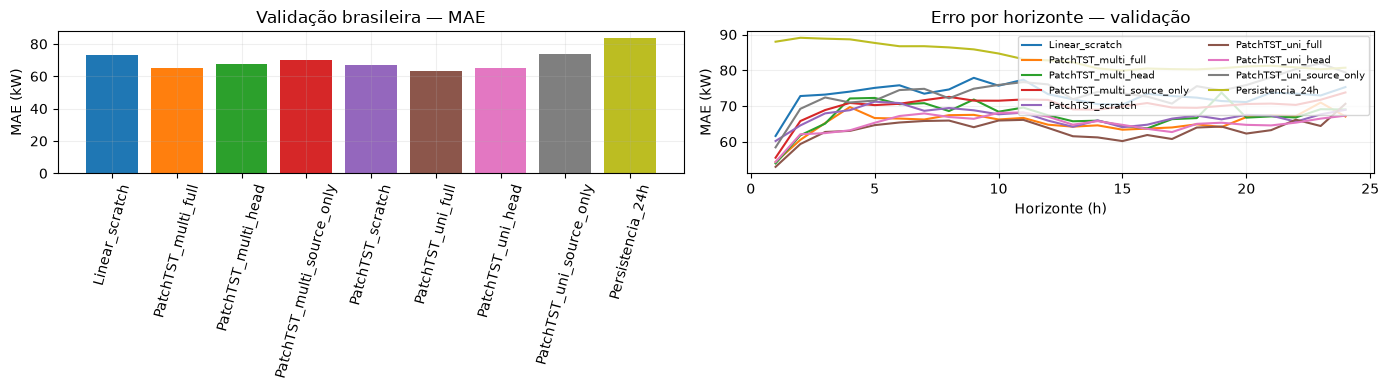

,seed,modelo,ganho_mae_vs_scratch_pct
0,42,Persistencia_24h,-24.785
1,42,Linear_scratch,-9.064
2,42,PatchTST_scratch,0.000
3,42,PatchTST_uni_source_only,-10.399
4,42,PatchTST_uni_head,3.038
5,42,PatchTST_uni_full,5.466
6,42,PatchTST_multi_source_only,-4.304
7,42,PatchTST_multi_head,-0.572
8,42,PatchTST_multi_full,2.375


In [6]:
def metricas_horizontes(dados,previsoes):
    linhas=[]
    for identificador,pred in previsoes.items():
        nome,seed=identificador.rsplit('_seed',1)
        dif=np.maximum(0,desnormalizar(pred,ESCALA_BR))-dados['y_kw']
        for h in range(HORIZONTE):
            linhas.append({'modelo':nome,'seed':int(seed),'horizonte_h':h+1,
                           'mae_kw':float(np.abs(dif[:,h]).mean()),
                           'rmse_kw':float(np.sqrt(np.square(dif[:,h]).mean()))})
    return pd.DataFrame(linhas)

horizontes=metricas_horizontes(VALIDACAO,PRED_VAL)
horizontes.to_csv(SAIDA/'mae_por_horizonte_validacao.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,4))
for nome,g in tabela_val.groupby('modelo'):
    axes[0].bar(nome,g.mae_kw.mean())
for nome,g in horizontes.groupby('modelo'):
    h=g.groupby('horizonte_h').mae_kw.mean()
    axes[1].plot(h.index,h.values,label=nome)
axes[0].set(title='Validação brasileira — MAE',ylabel='MAE (kW)')
axes[0].tick_params(axis='x',rotation=75)
axes[1].set(title='Erro por horizonte — validação',xlabel='Horizonte (h)',ylabel='MAE (kW)')
axes[1].legend(fontsize=7,ncol=2)
for ax in axes:ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(SAIDA/'comparacao_validacao.png',dpi=150,bbox_inches='tight');plt.show()

# Comparações emparelhadas pela MESMA semente e mesmas janelas.
linhas=[]
for seed in SEEDS:
    d=tabela_val.set_index(['modelo','seed'])
    ref=float(d.loc[('PatchTST_scratch',seed),'mae_kw'])
    for nome in MODELOS:
        mae=float(d.loc[(nome,seed),'mae_kw'])
        linhas.append({'seed':seed,'modelo':nome,'ganho_mae_vs_scratch_pct':100*(1-mae/ref)})
display(pd.DataFrame(linhas).round(3))
pd.DataFrame(linhas).to_csv(SAIDA/'ganho_validacao_vs_scratch.csv',index=False)


## 7. Comparação contextual com o 03_06 (opcional)

A tabela do 03_06 é carregada **somente se existir**. Só compare diretamente modelos se confirmar equivalência dos dados, horários, partições, tratamento, avaliação e sementes. O arquivo não altera nenhum treinamento.

In [7]:
path_tcn=RAIZ/'reports/tcc/03_06_transfer_learning_brasil'/f'L{HISTORICO}_H{HORIZONTE}'/'metricas_validacao.csv'
if path_tcn.is_file():
    antigo=pd.read_csv(path_tcn)
    subset=antigo[antigo.modelo.isin(['TCN_scratch','TCN_TL_full','CNN_LSTM_scratch','Persistencia_24h'])]
    print('03_06 (validação, somente contexto; verificar mesma amostragem de dados):')
    display(subset[['modelo','seed','n_janelas','mae_kw','rmse_kw','r2']].round(3))
else:
    print('Tabela do 03_06 não encontrada. Comparação externa opcional ignorada.')


03_06 (validação, somente contexto; verificar mesma amostragem de dados):


,modelo,seed,n_janelas,mae_kw,rmse_kw,r2
0,CNN_LSTM_scratch,42,395,68.853,131.118,0.818
1,TCN_TL_full,42,395,69.059,132.150,0.815
2,TCN_scratch,42,395,69.673,130.828,0.818
5,Persistencia_24h,42,395,83.624,164.865,0.711


## 8. TESTE BRASILEIRO — bloqueado por padrão

Depois de fixar todo o protocolo, defina `AVALIAR_TESTE_FINAL=True` e execute esta célula. Nenhum modelo é reajustado com dados de teste.

In [8]:
if not AVALIAR_TESTE_FINAL:
    print('Teste brasileiro preservado. Defina AVALIAR_TESTE_FINAL=True apenas após fechar a metodologia.')
else:
    raw_teste=ler_npz('brasil','teste')
    if not raw_val['timestamps_y'].max()<raw_teste['timestamps_y'].min():
        raise ValueError('Teste e validação se sobrepõem temporalmente')
    TESTE=normalizar(raw_teste,ESCALA_BR)
    previsoes_teste={}
    for seed in SEEDS:
        for nome in MODELOS:
            identificador=f'{nome}_seed{seed}'
            if nome=='Persistencia_24h':
                previsoes_teste[identificador]=persistencia_24(TESTE)
                continue
            modelo=criar_modelo(nome,seed)
            salvo=torch.load(SALVOS[identificador],map_location='cpu',weights_only=True)
            modelo.load_state_dict(salvo['model_state_dict'],strict=True)
            previsoes_teste[identificador]=prever(modelo,TESTE,BATCH_SIZE)
            del modelo
            if DEVICE.type=='cuda':torch.cuda.empty_cache()
    linhas_teste=[]
    for chave,pred in previsoes_teste.items():
        nome,seed=chave.rsplit('_seed',1)
        linhas_teste.append({'modelo':nome,'seed':int(seed),**resumo_metricas(TESTE,pred,ESCALA_BR)})
    tabela_teste=pd.DataFrame(linhas_teste).sort_values('mae_kw')
    display(tabela_teste.round(4))
    tabela_teste.to_csv(SAIDA/'metricas_teste_brasil_FINAL.csv',index=False)
    metricas_horizontes(TESTE,previsoes_teste).to_csv(SAIDA/'erros_por_horizonte_teste_FINAL.csv',index=False)
    # Subamostra menos sobreposta: emissões com distância mínima de 24h.
    emis=pd.to_datetime(TESTE['emissao'])
    indices=[];ultima=None
    for i,t in enumerate(emis):
        if ultima is None or t-ultima >= pd.Timedelta(hours=24):
            indices.append(i);ultima=t
    if indices:
        ds={k:(v[indices] if isinstance(v,np.ndarray) and len(v)==len(emis) else v) for k,v in TESTE.items()}
        linhas_ind=[]
        for chave,pred in previsoes_teste.items():
            nome,seed=chave.rsplit('_seed',1)
            linhas_ind.append({'modelo':nome,'seed':int(seed),**resumo_metricas(ds,pred[indices],ESCALA_BR)})
        pd.DataFrame(linhas_ind).to_csv(SAIDA/'teste_emissoes_24h_FINAL.csv',index=False)
        display(pd.DataFrame(linhas_ind).sort_values('mae_kw').round(4))
    print('Teste final salvo em:',SAIDA)


Teste brasileiro preservado. Defina AVALIAR_TESTE_FINAL=True apenas após fechar a metodologia.


## 9. Manifesto e limitações

- O pré-treinamento multivariado usa meteorologia **somente como objetivo auxiliar histórico**, não como entrada para previsão no Brasil.
- A diferença entre os pré-treinamentos mede uma associação experimental com o uso de canais meteorológicos, não necessariamente uma transferência causal de informação climática.
- Múltiplas janelas horárias compartilham registros; não devem ser tratadas como dias independentes.
- Se utilizar mais sementes, o `03_07` precisa ter gerado checkpoints correspondentes para cada uma.
- Resultados do artigo IEEE Access não são diretamente comparáveis porque os autores usaram muito mais dados australianos e cinco canais no destino.

In [9]:
manifesto={'etapa':'03_08','data_utc':datetime.now(timezone.utc).isoformat(),
           'config_patchtst':CONFIG_MODELO,'seeds':SEEDS,'max_epocas':EPOCAS,
           'normalizacao_brasil':ESCALA_BR,
           'checkpoint_australia':{str(k):{'arquivo':v['arquivo'],'sha256':v['hash']}
                                    for k,v in CKPTS.items()},
           'npz_brasil':{'treino':raw_train['hash_sha256'],'validacao':raw_val['hash_sha256']},
           'teste_bloqueado':not AVALIAR_TESTE_FINAL}
(SAIDA/'manifesto.json').write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding='utf-8')
print('Arquivos do experimento:',SAIDA)


Arquivos do experimento: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\reports\tcc\03_08_tl_patchtst_brasil\L240_H24
